# Assignment 1 — Working with Open Data

In this assignment you take a **real, public dataset**, ask questions of it, answer them, and document your work so that someone else could reproduce it.

**A few things to know before you start:**
- This course is about **data, not code.** The point of A1 is the analytical questions and what the numbers tell you about how people behave — *not* whether you remember Python syntax.
- You can do the analysis **in Python here, or in Google Sheets.** Every question below works either way. Pick whatever lets you think about the data instead of fighting the tool.
- You may use an **AI assistant** (ChatGPT, Claude, …) to help you write code — with rules. See *A note on using AI* at the bottom before you do.

**What you'll turn in** (committed to your `hcde-410` repo):
1. This notebook, with your answers filled in.
2. A short **README.md** describing your work.
3. A **LICENSE** file, and a note about the dataset's own license.

Your commit history is part of the record — commit as you go.

## Part 0 — Get the data

The data comes from [data.seattle.gov](https://data.seattle.gov/), the City of Seattle's open-data portal. We'll use the [Burke-Gilman Trail counter north of NE 70th St](https://data.seattle.gov/Transportation/Burke-Gilman-Trail-north-of-NE-70th-St-Bicycle-and/2z5v-ecg8), which records **bike and pedestrian traffic, by hour, by direction**.

We'll pull the data straight from the city's API rather than downloading a file by hand. That's a small reproducibility win: anyone who runs this notebook gets the same data the same way, and it's written down exactly where it came from.

In [13]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

In [14]:
# The dataset's API endpoint, and a query for one year of data (2019).
# You can paste the full URL into a browser to preview the raw data.
api_endpoint = "https://data.seattle.gov/resource/2z5v-ecg8.json?"
api_parameters = "$limit=50000&$where=date > '2019-01-01T00:00:00' AND date < '2020-01-01T00:00:00'"

response = requests.get(api_endpoint + api_parameters)
raw_data = response.json()
print("Downloaded", len(raw_data), "hourly records.")
# If this cell fails (e.g. the API is down), see the note below the next cell.

Downloaded 8759 hourly records.


Now load it into a **pandas DataFrame** — a table, like a spreadsheet you can compute with.

In [15]:
df = pd.DataFrame(raw_data)
df.head()

,date,bgt_north_of_ne_70th_total,ped_south,ped_north,bike_north,bike_south
0,2019-01-01T01:00:00.000,2,1,0,1,0
1,2019-01-01T02:00:00.000,1,0,0,0,1
2,2019-01-01T03:00:00.000,0,0,0,0,0
3,2019-01-01T04:00:00.000,1,0,0,1,0
4,2019-01-01T05:00:00.000,1,0,0,1,0


### Quick sanity checks

Whenever you work with data **you didn't create**, check that it means what you think before you analyze it. Two things need fixing here:
- the counts arrive as **text**, so we convert them to numbers;
- the `date` is a string, so we convert it to a real **datetime** and pull out the hour and weekday.

We'll also add tidy `bikes` and `peds` columns (north + south).

In [16]:
# convert the count columns from text to numbers
count_cols = ["bike_north", "bike_south", "ped_north", "ped_south", "bgt_north_of_ne_70th_total"]
df[count_cols] = df[count_cols].apply(pd.to_numeric, errors="coerce")

# convert the date string to a real datetime, and derive hour + weekday
df["date"] = pd.to_datetime(df["date"])
df["hour"] = df["date"].dt.hour
df["weekday"] = df["date"].dt.day_name()

# combined bike and pedestrian counts
df["bikes"] = df["bike_north"] + df["bike_south"]
df["peds"]  = df["ped_north"] + df["ped_south"]

df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8759 entries, 0 to 8758
Data columns (total 10 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   date                        8759 non-null   datetime64[ns]
 1   bgt_north_of_ne_70th_total  8759 non-null   int64         
 2   ped_south                   8759 non-null   int64         
 3   ped_north                   8759 non-null   int64         
 4   bike_north                  8759 non-null   int64         
 5   bike_south                  8759 non-null   int64         
 6   hour                        8759 non-null   int32         
 7   weekday                     8759 non-null   object        
 8   bikes                       8759 non-null   int64         
 9   peds                        8759 non-null   int64         
dtypes: datetime64[ns](1), int32(1), int64(7), object(1)
memory usage: 650.2+ KB


,date,bgt_north_of_ne_70th_total,ped_south,ped_north,bike_north,bike_south,hour,bikes,peds
count,8759,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000
mean,2019-07-02 12:00:00,58.423564,8.047380,8.363169,19.875671,22.137344,11.501313,42.013015,16.410549
min,2019-01-01 01:00:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2019-04-02 06:30:00,2.000000,0.000000,0.000000,0.000000,1.000000,6.000000,1.000000,0.000000
50%,2019-07-02 12:00:00,33.000000,5.000000,6.000000,9.000000,8.000000,12.000000,20.000000,11.000000
75%,2019-10-01 17:30:00,91.000000,13.000000,14.000000,31.000000,30.000000,17.500000,64.000000,27.000000
max,2019-12-31 23:00:00,1764.000000,1324.000000,782.000000,199.000000,961.000000,23.000000,1039.000000,1752.000000
std,NaN,73.656910,16.882468,13.164217,26.299728,34.080707,6.921886,56.534598,27.675776


**Look at what `describe()` tells you.** Are there hours with 0 traffic? Any missing values (a sensor can go offline)? Note anything odd — you'll want to mention data limitations later.

**No-code option:** run the next cell to save the cleaned data as a CSV, then open it in Google Sheets and do your analysis there. If you go this route, title your sheet **"A1 — [your name]"**, share it so anyone with the link can view, and paste the link into your written answers.

In [17]:
df.to_csv("bg_hourly_2019.csv", index=False)
print("Saved bg_hourly_2019.csv — a row per hour of 2019.")

Saved bg_hourly_2019.csv — a row per hour of 2019.


## Part 1 — One worked example: when do cyclists ride?

Here is the whole technique, **once**, so you can see the pattern. After this, the questions are yours.

The move is always the same: **group → summarize → plot → interpret.** In pandas that's a couple of lines (no loops needed).

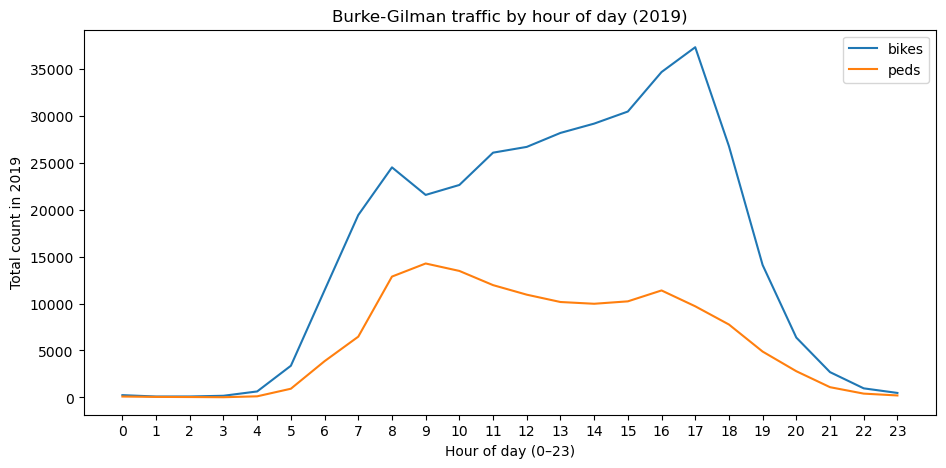

In [18]:
# group every row by its hour of day, and sum bikes and peds within each hour
by_hour = df.groupby("hour")[["bikes", "peds"]].sum()

by_hour.plot(figsize=(11, 5))
plt.title("Burke-Gilman traffic by hour of day (2019)")
plt.xlabel("Hour of day (0–23)")
plt.ylabel("Total count in 2019")
plt.xticks(range(0, 24))
plt.show()

**Now read the plot — this is the actual work.** What does the shape tell you? Do you see one peak or two? What might a double peak mean about *why* people are on the trail? That interpretation — turning a shape into a claim about human behavior — is what every question below is really asking for.

## Part 2 — Your analysis

Answer each question below. For every one:
1. **Show how you got there** — a pandas cell here, or (no-code) a link to your Google Sheet in the answer.
2. **Interpret it in 2–4 sentences** — what does this say about how people actually use the trail? The interpretation is the point, not the number.

There isn't a single right answer to most of these. Making a reasonable choice and *defending* it is the skill.

**Q1. When is the trail busiest, and when is it quietest?**
Decide what *busy* means to you first — a single hour? a stretch of the day? bikes and peds together, or separately? — and say why you chose that.

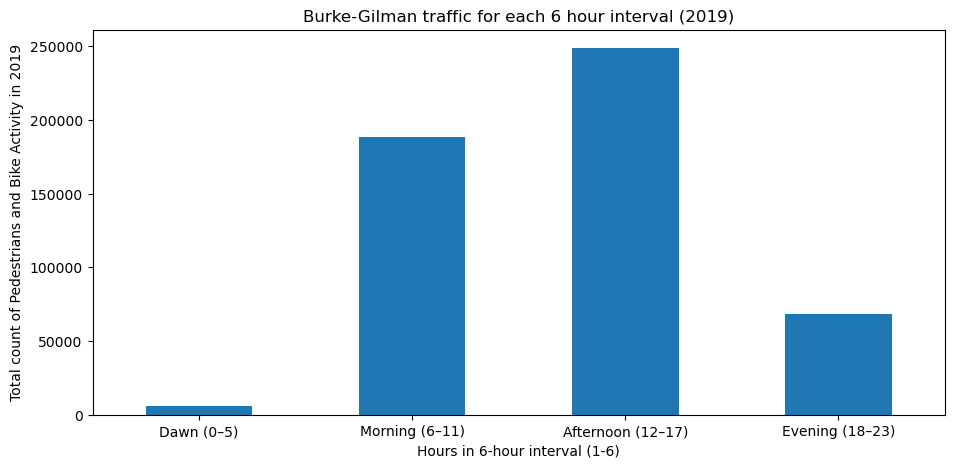

In [37]:
# Your code for Q1 (or put a Google Sheets link in your written answer below)
df["people"] = df["bikes"] + df["peds"] #group peds and bikes together

by_hour = df.groupby("hour")["people"].sum()

by_period = {
    "Dawn (0-5)": (0,5),
    "Morning (6-11)": (6, 11),
    "Afternoon (12-5)": (12, 17),
    "Evening (6-11)": (18, 23)
}

period_totals = {
    name: by_hour.loc[start:end].sum()
    for name, (start, end) in periods.items()
}

pd.Series(period_totals).plot(kind="bar", figsize=(11, 5))
plt.title("Burke-Gilman traffic for each 6 hour interval (2019)")
plt.xlabel("Hours in 6-hour interval (1-6)")
plt.ylabel("Total count of Pedestrians and Bike Activity in 2019")
plt.xticks(rotation=0)
plt.show()


*I divided the day into four six-hour periods to compare total traffic at different times of day and combined bike and pedestrian counts because both contribute to overall traffic use. Based on the graph, the afternoon (12pm-5pm) has the highest total traffic, while dawn(12 AM-5AM) has the lowest. I believe this makes sense in context because most people are sleeping at dawn, so they would not be on the trail, and most people would already be outside during the afternoon when the sun is still up, making it a more convenient time to use the trail in comparison to the morning or evening.*

***AI Prompt**: How do I show 6-hour intervals on a plot using panda for jupyter notebook if I have by_hour = df.groundpy("hour")["people"].sum() Should I use a bar chart to better interpret this?* 

***AI Original Output:***

***What I changed:** I changed this graph two times, from a line chart to a bar chart to better show the timeframe with most traffic. I originally labeled the intervals to show the corresponding hours so that it would be easier to understand the time the intervals take place in and then for the second version I labeled the y-axis to show that it was a total count*

---

#### **Q2. Do cyclists and pedestrians use the trail at different times of day?**
Compare their hourly patterns. If they differ, what might explain it?

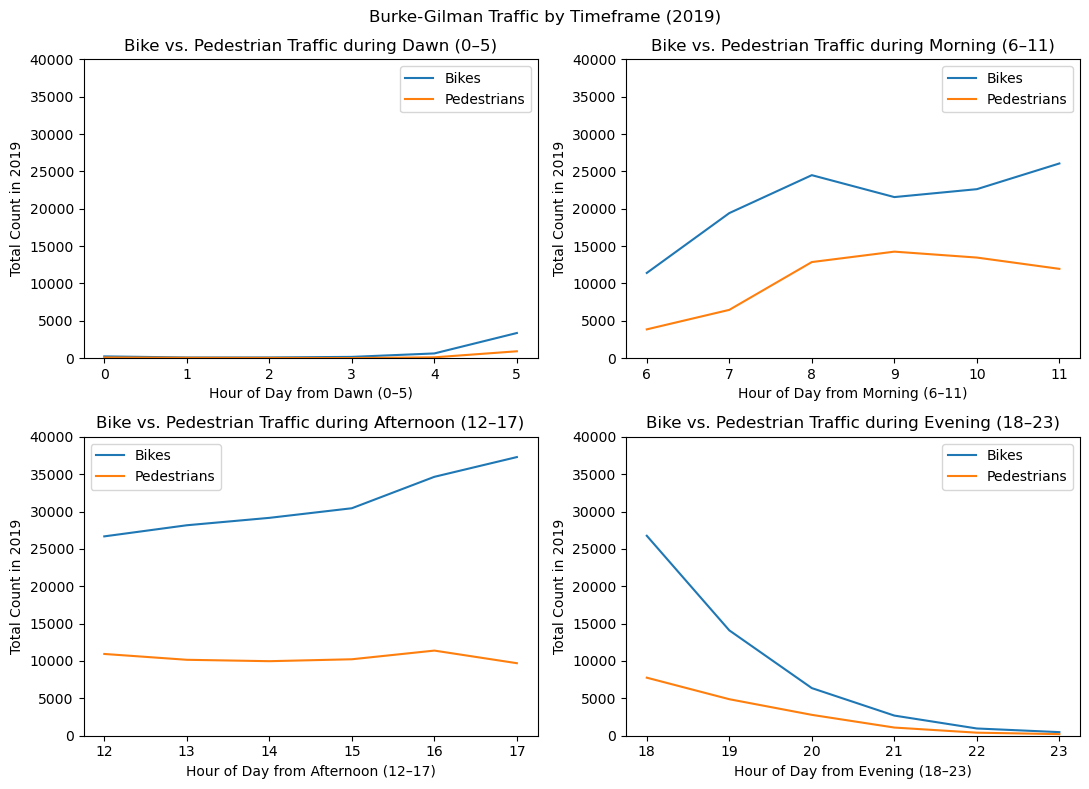

In [22]:
# Your code for Q2
by_bikes = df.groupby("hour")["bikes"].sum()
by_peds = df.groupby("hour")["peds"].sum()

periods = {
    "Dawn (0–5)": (0, 5),
    "Morning (6–11)": (6, 11),
    "Afternoon (12–17)": (12, 17),
    "Evening (18–23)": (18, 23)
}

fig, axes = plt.subplots(2, 2, figsize=(11, 8))

for ax, (title, (start, end)) in zip(axes.flat, periods.items()):
    hours = range(start, end + 1)

    ax.plot(hours, by_bikes.loc[start:end], label="Bikes")
    ax.plot(hours, by_peds.loc[start:end], label="Pedestrians")

    ax.set_title("Bike vs. Pedestrian Traffic during " + title)
    ax.set_xlabel("Hour of Day from " + title)
    ax.set_ylabel("Total Count in 2019")
    ax.set_ylim(bottom=0)
    ax.set_ylim(top=40000)
    ax.set_xticks(list(hours))
    ax.legend()

fig.suptitle("Burke-Gilman Traffic by Timeframe (2019)")
plt.tight_layout()
plt.show()

**Your Q2 answer:**

*The graphs show differences in the hourly patterns of cyclists and pedestrians, where cyclists have higher recorded counts than pedestrians. Cyclist counts decrease during the morning and continue to rise into the evening, while pedestrian counts increase in the morning and decline somewhat in the afternoon. One possible explanation is that cyclists and pedestrians use the trail for different purposes; for example, pedestrians may only use the trail in the morning, but use other routes to get home later in the day. However, the data alone can't exactly show why these patterns occur.*

***AI Prompt:** Based on previous prompt, show me how I could split these periods for "bike" vs "peds" to make 4 plots and show each interval of time. How can I make the x ticks correlate with the hour? How do I make the y-axis start from 0?*

***AI Original Output:***

***What I changed:** I adjusted the titles to accurately describe each line in the chart and also added the correct hours to the x-axis to show the range. I also added the upper range of the data to give it a better range*


#### **Q3. Commuting or recreation?**
Is there evidence people use the Burke-Gilman to *commute*, not just for fun? Compare **weekdays vs. weekends** (we made a `weekday` column for you), and maybe morning vs. evening. Define what a "commuting pattern" would look like in the data, then say whether you see it.

*Hint: `df.groupby("weekday")[["bikes","peds"]].sum()` gets you started. Weekends and weekdays will look different if commuting is real.*

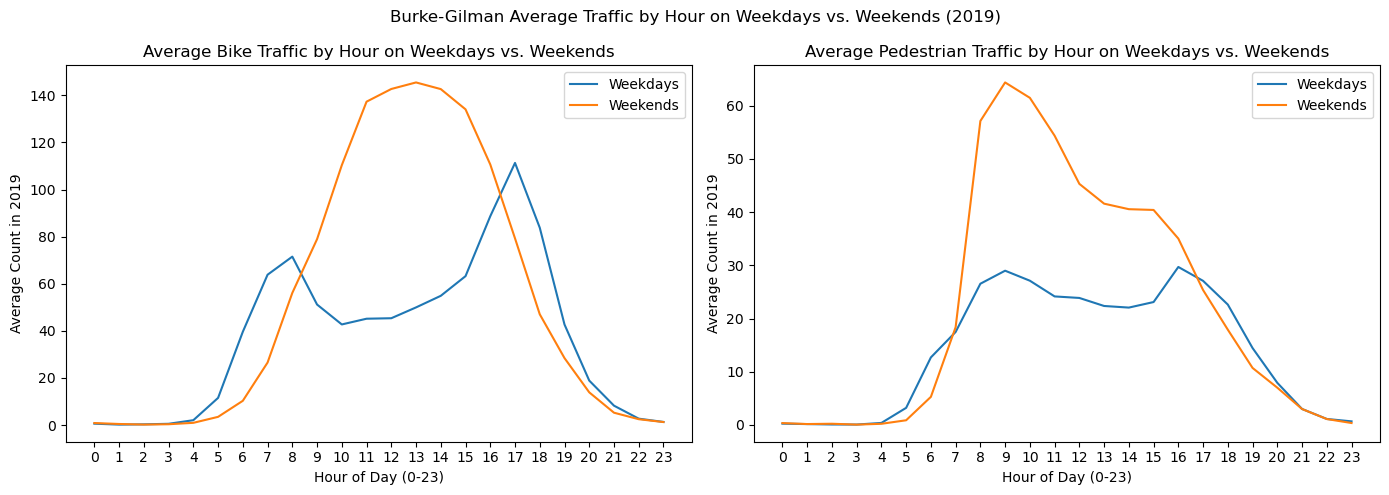

In [26]:
#Your code for Q3 

# Separate weekdays and weekends
weekdays = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
weekends = ["Saturday", "Sunday"]

weekday_data = df[df["weekday"].isin(weekdays)]
weekend_data = df[df["weekday"].isin(weekends)]

# Group by hour and calculate average traffic per day of the week
bikes_weekday = weekday_data.groupby("hour")["bikes"].mean()
bikes_weekend = weekend_data.groupby("hour")["bikes"].mean()

peds_weekday = weekday_data.groupby("hour")["peds"].mean()
peds_weekend = weekend_data.groupby("hour")["peds"].mean()

# Create two plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(bikes_weekday.index, bikes_weekday.values, label="Weekdays")
axes[0].plot(bikes_weekend.index, bikes_weekend.values, label="Weekends")
axes[0].set_title("Average Bike Traffic by Hour on Weekdays vs. Weekends")
axes[0].set_xlabel("Hour of Day (0-23)")
axes[0].set_ylabel("Average Count in 2019")
axes[0].set_xticks(range(24))
axes[0].legend()

axes[1].plot(peds_weekday.index, peds_weekday.values, label="Weekdays")
axes[1].plot(peds_weekend.index, peds_weekend.values, label="Weekends")
axes[1].set_title("Average Pedestrian Traffic by Hour on Weekdays vs. Weekends")
axes[1].set_xlabel("Hour of Day (0-23)")
axes[1].set_ylabel("Average Count in 2019")
axes[1].set_xticks(range(24))
axes[1].legend()


fig.suptitle("Burke-Gilman Average Traffic by Hour on Weekdays vs. Weekends (2019)")
plt.tight_layout()
plt.show()

**Your Q3 answer:**

*I looked at the morning and evening peaks on weekdays for cyclists and pedestrians as possible evidence of commuting, and higher, sustained daytime traffic on weekends for cyclists and a peak of activity during the morning for pedestrians as possible evidence of recreational use. The weekday and weekend graphs show differences in traffic patterns, where the trail has higher counts on the weekend, which could suggest that the trail is used for different purposes across the week, but more people use it during the weekend. However, the limitation is that the interpretation of traffic activity can't distinguish commuting from recreational use because the dataset doesn't record the reason why people are using the trail or where they're going.*

***AI Prompt:** How could I compare bikes and pedestrians by weekday vs. weekends by hour? There is a weekday variable that shows strings of the week*

***AI Original Output:***

***What I changed:** I adjusted the titles for the graphs to be more accurate and specific to what data is being shown in each plot so that it was easier to understand what is being graphed. It originally only wrote "Bike/Pedestrian Traffic by Hour" and didn't specify the year or the range of hours in the axes titles. I also simplified the code for calculating the mean*

#### **Q4. Direction and flow.**
The counter records **north vs. south** separately. Are mornings mostly one direction and evenings the other? What would that tell you about who's using the trail and where they're heading?

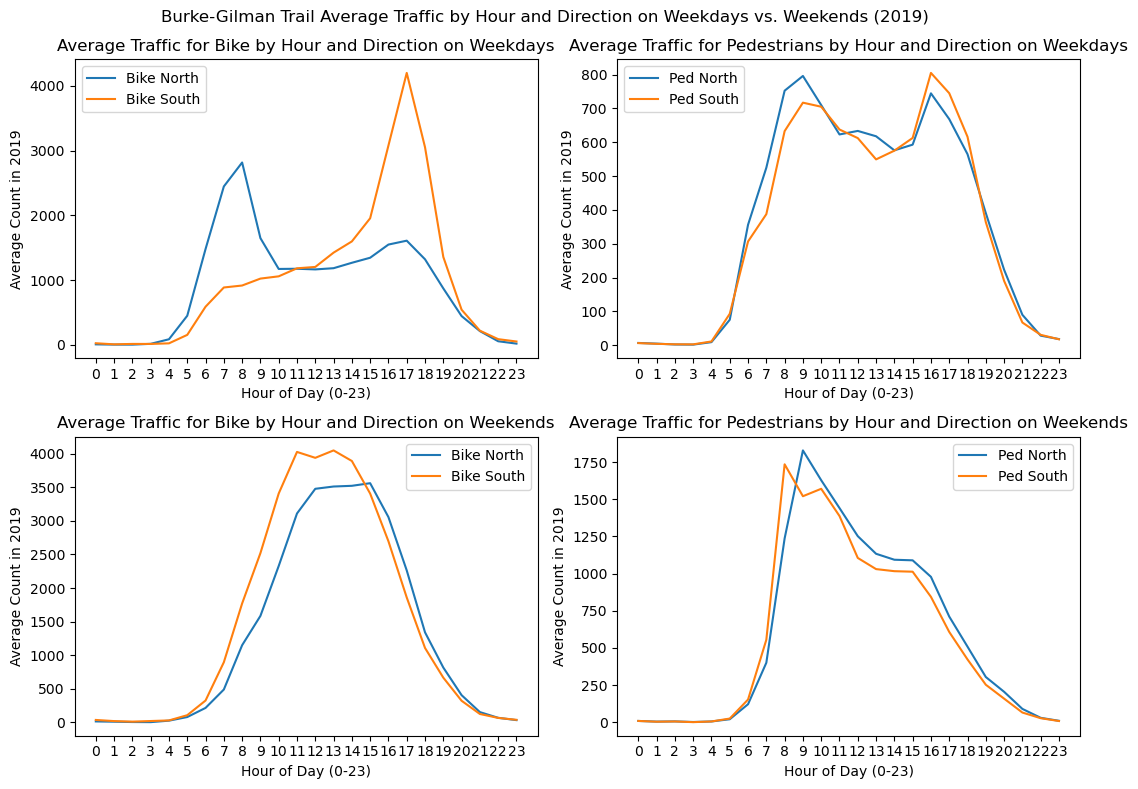

In [24]:
# Your code for Q4

# Separate weekdays and weekends
weekdays = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
weekends = ["Saturday", "Sunday"]

weekday_data = df[df["weekday"].isin(weekdays)]
weekend_data = df[df["weekday"].isin(weekends)]

# Group by hour and calculate average traffic per day of the week
bike_north_weekday = weekday_data.groupby(["weekday", "hour"])["bike_north"].sum().groupby("hour").mean()
bike_north_weekend = weekend_data.groupby(["weekday", "hour"])["bike_north"].sum().groupby("hour").mean()

bike_south_weekday = weekday_data.groupby(["weekday", "hour"])["bike_south"].sum().groupby("hour").mean()
bike_south_weekend = weekend_data.groupby(["weekday", "hour"])["bike_south"].sum().groupby("hour").mean()


ped_north_weekday = weekday_data.groupby(["weekday", "hour"])["ped_north"].sum().groupby("hour").mean()
ped_north_weekend = weekend_data.groupby(["weekday", "hour"])["ped_north"].sum().groupby("hour").mean()

ped_south_weekday = weekday_data.groupby(["weekday", "hour"])["ped_south"].sum().groupby("hour").mean()
ped_south_weekend = weekend_data.groupby(["weekday", "hour"])["ped_south"].sum().groupby("hour").mean()


# Create two plots
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

axes[0,0].plot(bike_north_weekday.index, bike_north_weekday.values, label="Bike North")
axes[0,0].plot(bike_south_weekday.index, bike_south_weekday.values, label="Bike South")
axes[0,0].set_title("Average Traffic for Bike by Hour and Direction on Weekdays")
axes[0,0].set_xlabel("Hour of Day (0-23)")
axes[0,0].set_ylabel("Average Count in 2019")
axes[0,0].set_xticks(range(24))
axes[0,0].legend()

axes[1,0].plot(bike_north_weekend.index, bike_north_weekend.values, label="Bike North")
axes[1,0].plot(bike_south_weekend.index, bike_south_weekend.values, label="Bike South")
axes[1,0].set_title("Average Traffic for Bike by Hour and Direction on Weekends")
axes[1,0].set_xlabel("Hour of Day (0-23)")
axes[1,0].set_ylabel("Average Count in 2019")
axes[1,0].set_xticks(range(24))
axes[1,0].legend()

axes[0,1].plot(ped_north_weekday.index, ped_north_weekday.values, label="Ped North")
axes[0,1].plot(ped_south_weekday.index, ped_south_weekday.values, label="Ped South")
axes[0,1].set_title("Average Traffic for Pedestrians by Hour and Direction on Weekdays")
axes[0,1].set_xlabel("Hour of Day (0-23)")
axes[0,1].set_ylabel("Average Count in 2019")
axes[0,1].set_xticks(range(24))
axes[0,1].legend()

axes[1,1].plot(ped_north_weekend.index, ped_north_weekend.values, label="Ped North")
axes[1,1].plot(ped_south_weekend.index, ped_south_weekend.values, label="Ped South")
axes[1,1].set_title("Average Traffic for Pedestrians by Hour and Direction on Weekends")
axes[1,1].set_xlabel("Hour of Day (0-23)")
axes[1,1].set_ylabel("Average Count in 2019")
axes[1,1].set_xticks(range(24))
axes[1,1].legend()


fig.suptitle("Burke-Gilman Trail Average Traffic by Hour and Direction on Weekdays vs. Weekends (2019)")
plt.tight_layout()
plt.show()

**Your Q4 answer:**

*On weekdays, a majority of traffic comes from cyclists using the trail, who seem to travel north in the morning and travel south in the evening. On weekends, traffic appears to be distributed throughout the day for cyclists, which may be consistent with recreational use from Q3, and it also shows that pedestrian activity peaks in the morning. The map of the Burke-Gilman trail shows that the south is near the University of Washington and the north goes all the way to Bothell, where there are more workplace buildings. These patterns could suggest that on the weekdays, a majority of this traffic may come from cyclists who live near the University of Washington and use the trail to commute to work, with few pedestrians using the trail, while on the weekends, many cyclists in general use the trail for fun throughout the day, with pedestrians using the trail for morning walks; this is also supported by my previous answers to Q1-Q3.*

***AI Prompt**: No AI prompt was used for this question, I rewrote the code from previous questions to better fit the question here*

## Part 3 — Make it reproducible

Good data work can be picked up and re-run by someone else. Two short deliverables:

**1. A `README.md`** in your `A1` folder. Use this template:

```
# A1 — Working with Open Data

**Dataset:** Burke-Gilman Trail counter north of NE 70th St
**Source:** https://data.seattle.gov/Transportation/.../2z5v-ecg8  (pulled YYYY-MM-DD)
**License / terms of use:** <find it on the dataset's page and note it here>

## Questions I asked
- ...

## How to re-run
Open `A1.ipynb` and run all cells (needs `requests`, `pandas`, `matplotlib`).
```

**2. A `LICENSE`** — keep the license file in this folder, and in your README **note the dataset's own license or terms of use** (open datasets almost always have one; find it on the dataset's page). Using open data responsibly means knowing what you're allowed to do with it — that's part of the assignment, not an afterthought.

### One more thing: read the data critically

In 3–4 sentences, name **one limitation or bias** in this dataset and how it could mislead someone who trusted it uncritically.

*(A sensor counts bodies, not intentions. It's one location on a long trail. Some hours may be missing when the counter was offline. A tandem bike counts once. What else?)* This is a warm-up for A2, where finding bias in data is the whole assignment.

**Your answer:**

*One bias this dataset is that the counters only record passages near the cameras rather than individuals. This could mislead someone if people using the trail went back and forth multiple times. This could affect the interpretations of the data, particularly trail use and busiest hours, making counts of cyclists or pedestrians higher than they were in reality and would mislead my hypothesis about more cyclists using the trail on the weekends than weekdays. Another limitation this dataset has is that it does not record the purposes of travel, so the motivation behind traffic can only be predicted by the patterns rather than insights*

## Optional — going further

If you want to push further (not required for full credit):
- Which **day of the week** is busiest? Is it the same for bikes and pedestrians?
- Has the trail gotten **busier over time**? (the data goes back to 2014 — change the year in the query)
- Do fewer people ride when it's **cold or wet**? (join with a Seattle [weather dataset](https://data.seattle.gov/))
- Compare with another counter — the [Fremont Bridge](https://data.seattle.gov/Transportation/Fremont-Bridge-Bicycle-Counter/65db-xm6k) or the [MTS Trail](https://data.seattle.gov/Transportation/MTS-Trail-west-of-I-90-Bridge-Bicycle-and-Pedestri/u38e-ybnc).

## A note on using AI

You may use an LLM (ChatGPT, Claude, …) to help you write code or make a plot. Treat it as a **tool you supervise, not an author you trust**:
- paste the **prompt** you used into a Markdown cell,
- **run** the output and check it against what you expected,
- note **what you changed and why**.

Here, AI is your assistant. In **A3** it becomes your subject of study. Code that runs but that you can't explain won't earn credit — the point is that *you* can ask a question of data and defend the answer.